# F106-Machine learning

## Análise da qualidade de vinhos

**UNIFOR**  
**Grupo:** 3  
**Participantes:** \
Pedro Enrique de Souza Simões - 2513694 \
Mykaelly Girão da Silva - 2631624 \
Fernando Luiz Silva de Lima - 2631661 \
Ezequias Pereira Sousa – 2523533 \
Eduardo Medeiros Alencar Holanda - 2523614 \
Nataniel Miranda da Silva - 2523548

### Objetivo
Investigar se características físico-químicas podem ser utilizadas para classificar a qualidade dos vinhos em duas classes, identificar agrupamentos naturais com K-Means e visualizar os dados em duas dimensões usando PCA.

## 1. Importação das bibliotecas


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
    silhouette_score
)
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

## 2. Carregamento da base de dados


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
df = pd.read_csv(r'/content/drive/MyDrive/ANÁLISE DE VINHO TINTO - UNIFOR/winequality-red.csv',sep=';')

## 3. Análise inicial da base

In [ ]:
print(f"Quantidade de registros: {df.shape[0]}")
print(f"Quantidade de atributos: {df.shape[1]}")
print("\nColunas:")
print(df.columns.tolist())
print("\nTipos de dados:")
print(df.dtypes)

Quantidade de registros: 1599
Quantidade de atributos: 12

Colunas:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']

Tipos de dados:
fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
dtype: object


In [ ]:
print("Informações gerais:")
df.info()

print("\nValores ausentes por coluna:")
display(df.isnull().sum().to_frame("valores_ausentes"))

print("Quantidade total de valores ausentes:", int(df.isnull().sum().sum()))
print("Quantidade de registros duplicados:", int(df.duplicated().sum()))

Informações gerais:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB

Valores ausentes por coluna:


,valores_ausentes
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


Quantidade total de valores ausentes: 0
Quantidade de registros duplicados: 240


In [ ]:
print("Estatísticas descritivas:")
display(df.describe().T)

Estatísticas descritivas:


,count,mean,std,min,25%,50%,75%,max
fixed acidity,1599.0,8.319637,1.741096,4.60000,7.1000,7.90000,9.200000,15.90000
volatile acidity,1599.0,0.527821,0.179060,0.12000,0.3900,0.52000,0.640000,1.58000
citric acid,1599.0,0.270976,0.194801,0.00000,0.0900,0.26000,0.420000,1.00000
residual sugar,1599.0,2.538806,1.409928,0.90000,1.9000,2.20000,2.600000,15.50000
chlorides,1599.0,0.087467,0.047065,0.01200,0.0700,0.07900,0.090000,0.61100
free sulfur dioxide,1599.0,15.874922,10.460157,1.00000,7.0000,14.00000,21.000000,72.00000
total sulfur dioxide,1599.0,46.467792,32.895324,6.00000,22.0000,38.00000,62.000000,289.00000
density,1599.0,0.996747,0.001887,0.99007,0.9956,0.99675,0.997835,1.00369
pH,1599.0,3.311113,0.154386,2.74000,3.2100,3.31000,3.400000,4.01000
sulphates,1599.0,0.658149,0.169507,0.33000,0.5500,0.62000,0.730000,2.00000


### Significado das principais variáveis

As colunas representam características físico-químicas do vinho, como acidez fixa, acidez volátil, ácido cítrico, açúcar residual, cloretos, dióxido de enxofre, densidade, pH, sulfatos e teor alcoólico. A coluna `quality` representa a nota de qualidade atribuída à amostra.

A coluna `quality` será utilizada para criar o alvo binário da classificação, mas não será usada como variável preditora, pois isso causaria vazamento de informação.

## 4. Distribuição da variável `quality`


Quantidade de amostras por nota:


,quantidade
quality,
3,10
4,53
5,681
6,638
7,199
8,18


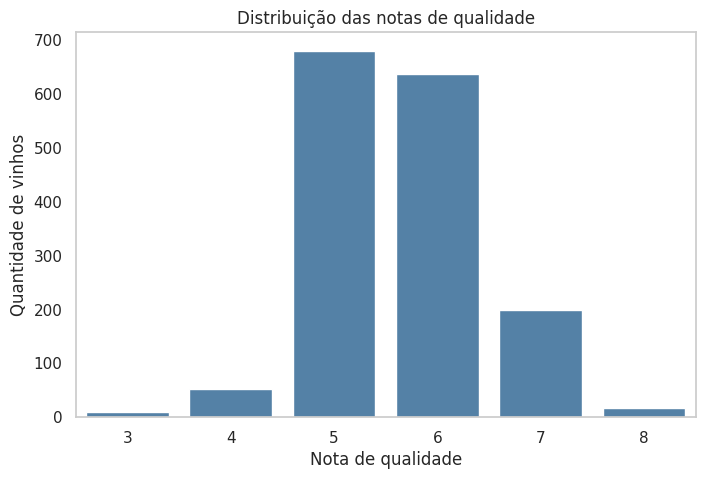

In [ ]:
quality_counts = df["quality"].value_counts().sort_index()
print("Quantidade de amostras por nota:")
display(quality_counts.to_frame("quantidade"))

plt.figure(figsize=(8, 5))
sns.barplot(x=quality_counts.index.astype(str), y=quality_counts.values, color="steelblue")
plt.title("Distribuição das notas de qualidade")
plt.xlabel("Nota de qualidade")
plt.ylabel("Quantidade de vinhos")
plt.grid(False)
plt.show()

## 5. Preparação do problema de classificação

Conforme solicitado:

- `quality < 6` corresponde à **qualidade baixa**, codificada como `0`;
- `quality >= 6` corresponde à **qualidade alta**, codificada como `1`.

In [ ]:
df["quality_class"] = (df["quality"] >= 6).astype(int)

display(df[["quality", "quality_class"]].head(10))

,quality,quality_class
0,5,0
1,5,0
2,5,0
3,6,1
4,5,0
5,5,0
6,5,0
7,7,1
8,7,1
9,5,0


,quantidade,percentual
Qualidade baixa (0),744,46.53
Qualidade alta (1),855,53.47


/tmp/ipykernel_669/1735505592.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=["Baixa (0)", "Alta (1)"], y=class_counts.values, palette="Set2")


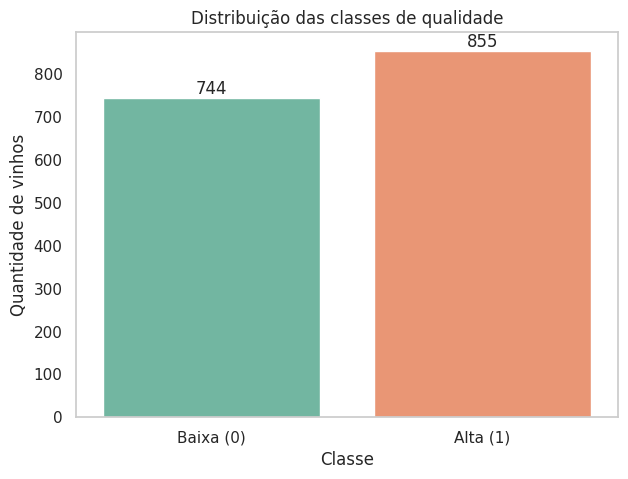

In [ ]:
class_counts = df["quality_class"].value_counts().sort_index()
class_percentages = df["quality_class"].value_counts(normalize=True).sort_index() * 100

class_summary = pd.DataFrame({
    "quantidade": class_counts,
    "percentual": class_percentages.round(2)
})
class_summary.index = ["Qualidade baixa (0)", "Qualidade alta (1)"]

display(class_summary)

plt.figure(figsize=(7, 5))
ax = sns.barplot(x=["Baixa (0)", "Alta (1)"], y=class_counts.values, palette="Set2")
plt.title("Distribuição das classes de qualidade")
plt.xlabel("Classe")
plt.ylabel("Quantidade de vinhos")
for i, value in enumerate(class_counts.values):
    ax.text(i, value, str(value), ha="center", va="bottom")
plt.grid(False)
plt.show()

### Entendendo a distribuição das classes

Agora vamos olhar quantos vinhos ficaram em cada grupo. Se os números forem parecidos, podemos dizer que as classes estão relativamente equilibradas. Se um grupo tiver muitos vinhos a mais que o outro, significa que os dados estão desequilibrados.
Essa informação é importante porque um modelo pode parecer bom simplesmente por acertar a classe que aparece mais vezes. Por isso, na hora de separar os dados para treinamento e teste, vamos usar uma divisão que mantenha uma proporção parecida das duas classes nos dois conjuntos.
Também vamos olhar para precisão, recall e F1-score, e não somente para a acurácia, antes de escolher o melhor modelo.

## 6. Separando as informações para o modelo

Agora vamos separar o que o modelo vai usar para fazer as previsões e qual será a resposta que ele precisa aprender. \
As características físico-químicas, como acidez, pH, sulfatos e teor alcoólico, ficam em `X`. Já a variável `quality_class`, que indica se o vinho é de qualidade baixa ou alta, fica em y.\
A coluna original quality não entra em `X`. Isso acontece porque foi justamente a partir dela que criamos `quality_class`. Se deixássemos quality no modelo, seria como entregar a resposta antes de ele fazer a previsão. Por isso, retiramos essa coluna para que o resultado seja mais justo. \
Depois, vamos separar os dados em duas partes: 80% para o modelo aprender e 20% para testar se ele consegue fazer previsões em dados que ainda não viu. \
Também vamos usar `stratify=y`. Em palavras simples, isso ajuda a manter uma proporção parecida de vinhos de qualidade baixa e alta tanto na parte de treinamento quanto na parte de teste.


In [ ]:
feature_columns = [column for column in df.columns if column not in ["quality", "quality_class"]]
X = df[feature_columns]
y = df["quality_class"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Variáveis utilizadas em X:")
print(feature_columns)
print(f"\nFormato de X_train: {X_train.shape}")
print(f"Formato de X_test: {X_test.shape}")
print(f"Formato de y_train: {y_train.shape}")
print(f"Formato de y_test: {y_test.shape}")

print("\nDistribuição das classes em y_train:")
print(y_train.value_counts(normalize=True).sort_index().round(3))
print("\nDistribuição das classes em y_test:")
print(y_test.value_counts(normalize=True).sort_index().round(3))

Variáveis utilizadas em X:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']

Formato de X_train: (1279, 11)
Formato de X_test: (320, 11)
Formato de y_train: (1279,)
Formato de y_test: (320,)

Distribuição das classes em y_train:
quality_class
0    0.465
1    0.535
Name: proportion, dtype: float64

Distribuição das classes em y_test:
quality_class
0    0.466
1    0.534
Name: proportion, dtype: float64


## 7. Pré-processamento

Antes de treinar os modelos, precisamos deixar as variáveis em uma escala parecida. Isso é importante porque algumas características do vinho têm valores bem maiores ou menores que outras.
Na Regressão Logística, vamos fazer essa padronização. Assim, nenhuma variável acaba tendo mais peso apenas porque possui números maiores. Essa transformação será feita usando o `StandardScaler` dentro de um `Pipeline`.
O `Pipeline` organiza esse processo: primeiro os dados são padronizados e depois entram no modelo. Além disso, a padronização aprende os valores usando apenas os dados de treinamento. Depois, ela é aplicada aos dados de teste sem que o modelo tenha acesso às respostas desses dados.
A `Árvore de Decisão` funciona de um jeito diferente. Ela toma decisões criando pontos de corte nas variáveis, então não precisa que os dados estejam na mesma escala. Por isso, nesse modelo, vamos usar os dados diretamente, sem padronização.

## 8. Treinamento dos modelos supervisionados

Escolhemos os seguintes modelos:

1. **Regressão Logística**, como modelo linear e interpretável;
2. **Árvore de Decisão**, como modelo capaz de representar relações não lineares por regras de decisão.

In [ ]:
models = {
    "Regressão Logística": Pipeline([
        ("padronizacao", StandardScaler()),
        ("modelo", LogisticRegression(max_iter=1000, random_state=42))
    ]),
    "Árvore de Decisão": DecisionTreeClassifier(
        random_state=42,
        max_depth=5
    )
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"Modelo treinado: {name}")

Modelo treinado: Regressão Logística
Modelo treinado: Árvore de Decisão


## 9. Avaliação dos modelos


- **Acurácia:** proporção de previsões corretas;
- **Precisão:** entre as amostras classificadas como positivas, proporção que realmente pertence à classe alta;
- **Recall:** entre as amostras realmente positivas, proporção identificada pelo modelo;
- **F1-score:** média harmônica entre precisão e recall;
- **Matriz de confusão:** mostra acertos e erros por classe.

As métricas de precisão, recall e F1-score utilizam `average="binary"`, considerando a classe `1` como qualidade alta.

In [ ]:
results = []
predictions = {}

for name, model in models.items():
    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    results.append({
        "Modelo": name,
        "Acurácia": accuracy_score(y_test, y_pred),
        "Precisão": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0)
    })

results_df = pd.DataFrame(results).set_index("Modelo")
display(results_df.round(4))

,Acurácia,Precisão,Recall,F1-score
Modelo,,,,
Regressão Logística,0.7406,0.7683,0.7368,0.7522
Árvore de Decisão,0.7312,0.7545,0.7368,0.7456


Regressão Logística
                 precision    recall  f1-score   support

Qualidade baixa       0.71      0.74      0.73       149
 Qualidade alta       0.77      0.74      0.75       171

       accuracy                           0.74       320
      macro avg       0.74      0.74      0.74       320
   weighted avg       0.74      0.74      0.74       320



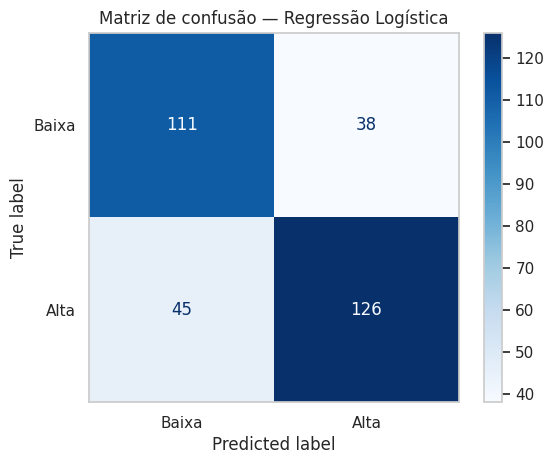

Árvore de Decisão
                 precision    recall  f1-score   support

Qualidade baixa       0.71      0.72      0.72       149
 Qualidade alta       0.75      0.74      0.75       171

       accuracy                           0.73       320
      macro avg       0.73      0.73      0.73       320
   weighted avg       0.73      0.73      0.73       320



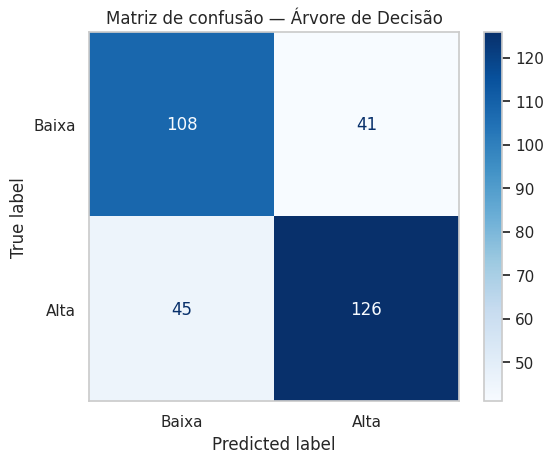

In [ ]:
for name, y_pred in predictions.items():
    print("=" * 70)
    print(name)
    print("=" * 70)
    print(classification_report(
        y_test,
        y_pred,
        target_names=["Qualidade baixa", "Qualidade alta"],
        zero_division=0
    ))

    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Baixa", "Alta"]
    )
    disp.plot(cmap="Blues", values_format="d")
    plt.title(f"Matriz de confusão — {name}")
    plt.grid(False)
    plt.show()

### Comparação dos modelos

A decisão sobre o melhor modelo deve considerar as quatro métricas, especialmente o F1-score, que combina precisão e recall. A tabela acima contém os valores reais obtidos na execução. Não se deve declarar um vencedor antes de observar esses valores.

## 10. Interpretação da importância das variáveis

A Árvore de Decisão possui uma medida de importância das variáveis. Essa medida indica quanto cada variável contribuiu para as divisões realizadas pela árvore, mas não prova causalidade.

,variavel,importancia
10,alcohol,0.477536
9,sulphates,0.206571
1,volatile acidity,0.123916
6,total sulfur dioxide,0.093307
8,pH,0.023453
2,citric acid,0.016683
0,fixed acidity,0.014300
7,density,0.012501
3,residual sugar,0.012141
5,free sulfur dioxide,0.010718


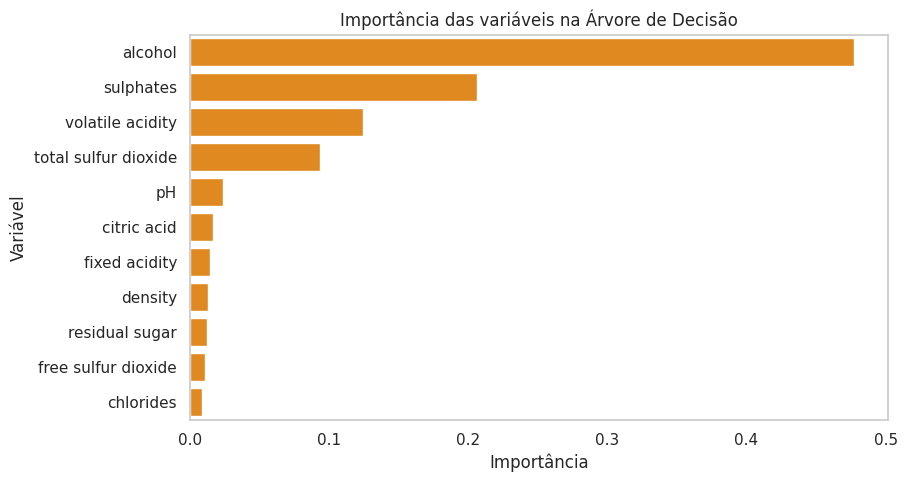

In [ ]:
tree_model = models["Árvore de Decisão"]
importance_df = pd.DataFrame({
    "variavel": feature_columns,
    "importancia": tree_model.feature_importances_
}).sort_values("importancia", ascending=False)

display(importance_df)

plt.figure(figsize=(9, 5))
sns.barplot(data=importance_df, x="importancia", y="variavel", color="darkorange")
plt.title("Importância das variáveis na Árvore de Decisão")
plt.xlabel("Importância")
plt.ylabel("Variável")
plt.grid(False)
plt.show()

## 11. Aprendizado não supervisionado com K-Means

Nesta etapa, as colunas `quality` e `quality_class` não serão utilizadas. O K-Means trabalhará somente com as características físico-químicas dos vinhos.

Como as variáveis possuem escalas diferentes, os dados serão padronizados antes do agrupamento. Serão testados pelo menos dois valores de K, neste caso `K=2` e `K=3`.

In [ ]:
X_unsupervised = df[feature_columns].copy()
scaler_kmeans = StandardScaler()
X_unsupervised_scaled = scaler_kmeans.fit_transform(X_unsupervised)

kmeans_models = {}
kmeans_labels = {}
kmeans_summary = []

for k in [2, 3]:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_unsupervised_scaled)

    kmeans_models[k] = kmeans
    kmeans_labels[k] = labels

    kmeans_summary.append({
        "K": k,
        "Inércia": kmeans.inertia_,
        "Silhouette": silhouette_score(X_unsupervised_scaled, labels)
    })

kmeans_summary_df = pd.DataFrame(kmeans_summary).set_index("K")
display(kmeans_summary_df.round(4))

,Inércia,Silhouette
K,,
2,14330.1198,0.2137
3,12629.9746,0.1892


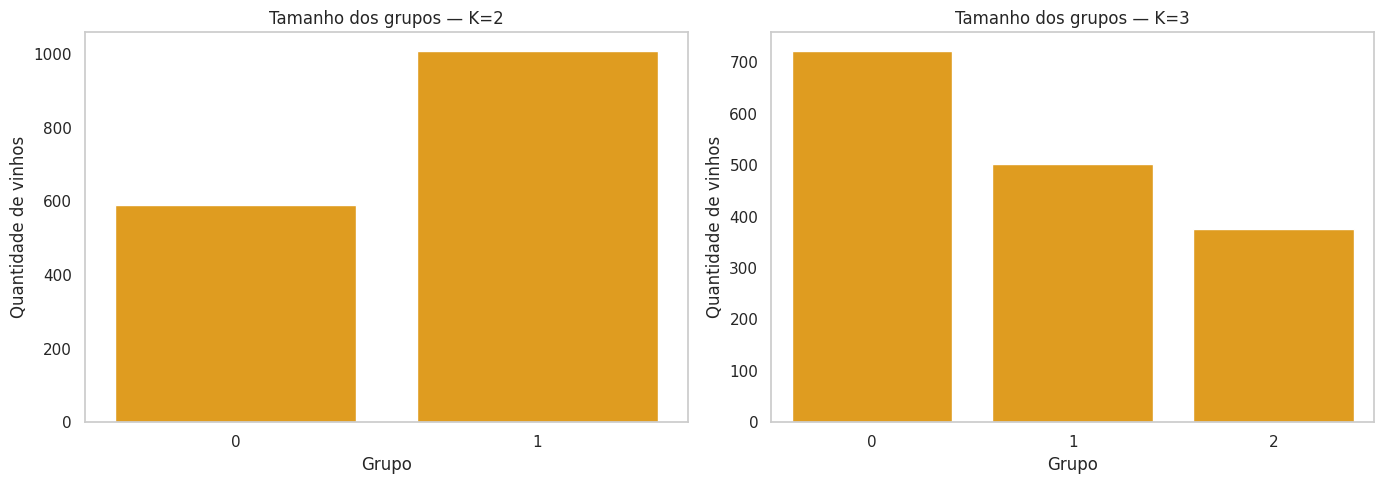

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, k in zip(axes, [2, 3]):
    counts = pd.Series(kmeans_labels[k]).value_counts().sort_index()
    sns.barplot(x=counts.index.astype(str), y=counts.values, ax=ax, color="orange")
    ax.set_title(f"Tamanho dos grupos — K={k}")
    ax.set_xlabel("Grupo")
    ax.set_ylabel("Quantidade de vinhos")
    ax.grid(False)

plt.tight_layout()
plt.grid(False)
plt.show()

### Comparação dos agrupamentos

Ao comparar os valores de K, podemos observar:

- como muda a quantidade de grupos;
- o tamanho de cada grupo;
- a silhueta, que fornece uma indicação de separação e coesão dos grupos;
- se os grupos representam perfis físico-químicos diferentes.

Os agrupamentos não precisam coincidir com as classes de qualidade, pois o K-Means não recebeu a informação de `quality` nem de `quality_class`.

In [ ]:
# Comparação exploratória entre os grupos do K-Means e as classes de qualidade.
# A qualidade NÃO foi usada para formar os grupos; ela aparece apenas nesta análise posterior.
for k in [2, 3]:
    comparison = pd.crosstab(
        pd.Series(kmeans_labels[k], name=f"grupo_k{k}"),
        df["quality_class"].map({0: "Baixa", 1: "Alta"}),
        normalize="index"
    ) * 100
    print(f"Distribuição das classes de qualidade dentro dos grupos — K={k} (%)")
    display(comparison.round(2))

Distribuição das classes de qualidade dentro dos grupos — K=2 (%)


quality_class,Alta,Baixa
grupo_k2,,
0,66.44,33.56
1,45.89,54.11


Distribuição das classes de qualidade dentro dos grupos — K=3 (%)


quality_class,Alta,Baixa
grupo_k3,,
0,51.80,48.20
1,70.72,29.28
2,33.60,66.40


## 12. Redução de dimensionalidade com PCA

O PCA é uma técnica que ajuda a resumir várias informações em apenas algumas dimensões. Neste trabalho, temos várias características dos vinhos, como acidez, pH, sulfatos e teor alcoólico. Como seria difícil visualizar tudo isso ao mesmo tempo, o PCA transforma essas informações em duas novas dimensões chamadas de Componente Principal 1 e Componente Principal 2.\
Com isso, conseguimos colocar os vinhos em um gráfico e observar se eles ficam mais próximos, mais separados ou misturados entre si.\
Depois, vamos colorir o gráfico de acordo com os grupos encontrados pelo `K-Means` usando `K=2`. Também será feita uma visualização considerando as classes de qualidade.\
Essa visualização ajuda a entender melhor os dados, mas é importante lembrar que várias informações estão sendo resumidas em apenas duas dimensões. Por isso, alguns detalhes dos dados originais podem não aparecer completamente no gráfico.

In [ ]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_unsupervised_scaled)

pca_df = pd.DataFrame(X_pca, columns=["PC1", "PC2"])
pca_df["grupo_k2"] = kmeans_labels[2]
pca_df["quality_class"] = df["quality_class"].values

print("Variância explicada por cada componente:")
print(pd.Series(
    pca.explained_variance_ratio_,
    index=["PC1", "PC2"]
).round(4))
print(f"Variância explicada acumulada pelas duas componentes: {pca.explained_variance_ratio_.sum():.4f}")

display(pca_df.head())

Variância explicada por cada componente:
PC1    0.2817
PC2    0.1751
dtype: float64
Variância explicada acumulada pelas duas componentes: 0.4568


,PC1,PC2,grupo_k2,quality_class
0,-1.619530,0.450950,1,0
1,-0.799170,1.856553,1,0
2,-0.748479,0.882039,1,0
3,2.357673,-0.269976,0,1
4,-1.619530,0.450950,1,0


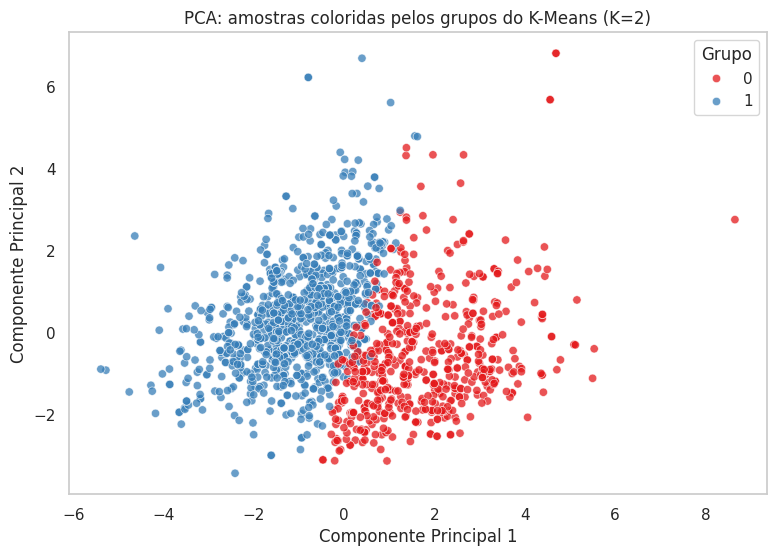

In [ ]:
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="grupo_k2",
    palette="Set1",
    alpha=0.75
)
plt.title("PCA: amostras coloridas pelos grupos do K-Means (K=2)")
plt.xlabel("Componente Principal 1")
plt.ylabel("Componente Principal 2")
plt.legend(title="Grupo")
plt.grid(False)
plt.show()

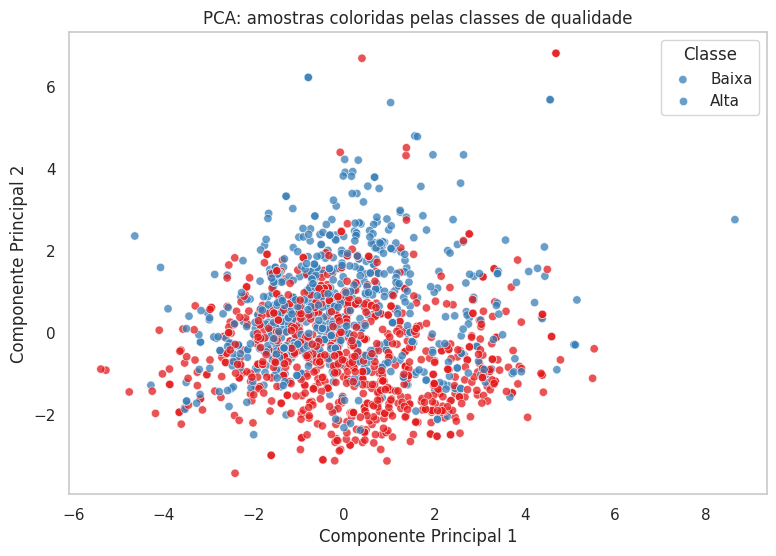

In [ ]:
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="quality_class",
    palette={0: "#377eb8", 1: "#e41a1c"},
    alpha=0.75
)
plt.title("PCA: amostras coloridas pelas classes de qualidade")
plt.xlabel("Componente Principal 1")
plt.ylabel("Componente Principal 2")
plt.legend(title="Classe", labels=["Baixa", "Alta"])
plt.grid(False)
plt.show()

### Interpretação do PCA

Agora vamos observar o gráfico para entender como os vinhos ficaram distribuídos.\
Vamos verificar se aparecem regiões mais separadas ou se os pontos ficam muito misturados. Também vamos observar se os grupos formados pelo K-Means parecem diferentes ou se existe muita sobreposição entre eles.\
Outro ponto importante é a porcentagem de informação explicada pelas duas componentes principais. Quanto maior essa porcentagem, melhor o gráfico consegue resumir os dados originais.\
Mesmo que apareçam algumas regiões separadas, os pontos podem continuar se misturando. Nesse caso, significa que o PCA ajuda a visualizar os dados, mas não consegue separar perfeitamente todos os tipos de vinho em apenas duas dimensões.

## 13. Conclusão orientada pelos resultados


In [ ]:
best_model_by_f1 = results_df["F1-score"].idxmax()
best_f1 = results_df.loc[best_model_by_f1, "F1-score"]

print("RESUMO PARA A CONCLUSÃO")
print("-" * 70)
print(f"Modelo com maior F1-score: {best_model_by_f1} ({best_f1:.4f})")
print(f"Variância explicada pelo PCA com duas componentes: {pca.explained_variance_ratio_.sum():.4f}")
print("\nMétricas dos modelos:")
display(results_df.round(4))
print("\nSilhouette dos agrupamentos:")
display(kmeans_summary_df[["Silhouette"]].round(4))

RESUMO PARA A CONCLUSÃO
----------------------------------------------------------------------
Modelo com maior F1-score: Regressão Logística (0.7522)
Variância explicada pelo PCA com duas componentes: 0.4568

Métricas dos modelos:


,Acurácia,Precisão,Recall,F1-score
Modelo,,,,
Regressão Logística,0.7406,0.7683,0.7368,0.7522
Árvore de Decisão,0.7312,0.7545,0.7368,0.7456



Silhouette dos agrupamentos:


,Silhouette
K,
2,0.2137
3,0.1892


### Análise conclusória


Respondendo às questões que motivaram o trabalho, os resultados indicam que as características físico-químicas dos vinhos podem ser utilizadas para classificar sua qualidade entre as categorias baixa e alta, embora com desempenho moderado. Entre os modelos avaliados, a Regressão Logística apresentou o melhor resultado geral, com F1-score de 75,22%. A escolha do modelo, portanto, não foi baseada apenas na acurácia, mas na análise conjunta das métricas de desempenho.

Na análise com K-Means, foram testados K=2 e K=3, e os resultados mostraram que existem agrupamentos de vinhos com características físico-químicas semelhantes, mas que esses grupos não coincidem perfeitamente com as classes de qualidade. Isso ocorre porque o algoritmo não recebeu a informação sobre a qualidade dos vinhos durante a formação dos grupos. Com K=3, foi possível observar uma diferenciação mais clara entre alguns perfis, com um grupo apresentando maior concentração de vinhos de qualidade alta, outro maior concentração de qualidade baixa e um terceiro mais equilibrado. Entretanto, a análise da silhueta mostrou que ainda existe sobreposição entre os grupos.

O PCA permitiu reunir diversas características dos vinhos em apenas duas dimensões para facilitar a visualização dos dados. A primeira componente explicou 28,17% da variância e a segunda 17,51%, totalizando 45,68% da variância dos dados. Dessa forma, o PCA permitiu visualizar alguns padrões e uma separação parcial entre os grupos, mas a sobreposição entre os pontos mostrou que as duas primeiras componentes não são suficientes para separar completamente os vinhos de qualidade alta e baixa.

Entre as limitações do trabalho, destaca-se a transformação da nota original de qualidade em apenas duas classes, simplificando uma variável que originalmente é representada por uma escala. Além disso, os resultados dependem da divisão realizada entre os conjuntos de treinamento e teste. A existência de 240 registros duplicados antes dessa divisão também representa um ponto de atenção, pois, caso registros idênticos tenham sido distribuídos entre os dois conjuntos, isso pode ter contribuído para uma estimativa de desempenho mais favorável.

Como possibilidades de trabalhos futuros, poderiam ser utilizadas técnicas de validação cruzada, verificações da presença de registros semelhantes entre treinamento e teste, outras estratégias de tratamento dos dados e diferentes modelos de classificação. Também poderiam ser investigadas outras formas de representar a qualidade dos vinhos e outras técnicas de redução de dimensionalidade.

De forma geral, os resultados mostram que técnicas de Machine Learning podem ser utilizadas como ferramentas de apoio à análise e à triagem da qualidade dos vinhos. Entretanto, os modelos não devem substituir a avaliação especializada, especialmente diante da sobreposição observada entre as classes e das limitações identificadas no conjunto de dados.